# Barrido de medias móviles

**Pregunta:** entre mantener siempre (B&H) y 6/200, ¿la rentabilidad baja de forma gradual, o hay alguna combinación de medias que rinde más, o casi lo mismo con bastante menos volatilidad?

**Método:** se simula la regla *dentro si SMA(rápida) > SMA(lenta)* para una rejilla de combinaciones, todas sobre el mismo periodo, y se comparan:

1. **Globalmente:** métricas sobre todo el periodo (mapas de calor y rentabilidad frente a volatilidad).
2. **En el tiempo:** rentabilidad en ventanas móviles de `VENTANA` años frente a B&H, y estabilidad entre la primera y la segunda mitad del periodo.

Cuanto más lenta es la media lenta, menos se sale del mercado: en el límite, la regla converge a B&H. Por eso la rejilla llega a medias lentas de 400 sesiones.

**Cuidado con el sobreajuste.** Con unas 50 combinaciones sobre un único histórico, la mejor saldrá mejor en parte por azar. Lo que conviene buscar son **zonas amplias** de buenos resultados que se mantengan en ambas mitades del periodo, no la casilla ganadora.

Mismos supuestos que `analisis.ipynb`: retraso de ejecución, comisión y rentabilidad de la liquidez configurables.

In [1]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from nucleo.backtest import metricas, rent_movil, simular
from nucleo.datos import posicion, precios

pd.set_option("display.width", 200)

## Configuración

In [2]:
ACTIVOS = {
    "sp500": ("SPY", "EURUSD=X"),  # S&P 500 con dividendos, en euros
    "oro": ("GLD", "EURUSD=X"),    # oro (ETF GLD), en euros
}
ACTIVO = "sp500"
TICKER, DIVISA = ACTIVOS[ACTIVO]

# Rejilla amplia (primer barrido):
# RAPIDAS = [1, 3, 6, 10, 20, 30, 50]          # 1 = el propio precio
# LENTAS = [50, 100, 150, 200, 250, 300, 400]
# Zoom en medias lentas (el primer barrido apuntaba a la esquina 50/400):
RAPIDAS = [20, 30, 50, 75, 100, 150]
LENTAS = [300, 400, 500, 600, 800]
RETRASO = 2           # sesiones entre la señal y la ejecución
COMISION = 0.0        # coste por operación, en tanto por uno
TIPO_LIQUIDEZ = 0.0   # rentabilidad anual mientras se está fuera
VENTANA = 3           # años de las ventanas móviles
DESTACADAS = [(6, 200), (50, 400), (75, 500), (50, 600)]  # combinaciones a seguir en detalle
GRAFICO_SENALES = [(50, 400), (75, 500), (50, 600)]       # combinaciones lentas para ver sus señales

## Simulación de todas las combinaciones

In [3]:
precio = precios(TICKER, DIVISA, periodo="max")
combinaciones = [(a, b) for a in RAPIDAS for b in LENTAS if a < b]
combinaciones += [k for k in DESTACADAS + GRAFICO_SENALES if k not in combinaciones]

# Periodo común: desde que la media más lenta tiene valor.
inicio = precio.index[max(b for _, b in combinaciones) - 1]
rent = precio.pct_change().loc[inicio:].iloc[RETRASO + 1:]

diarias, ops = {"B&H": rent}, {"B&H": pd.Series(False, index=rent.index)}
for a, b in combinaciones:
    dentro = posicion(precio, ((a, b),))
    diarias[(a, b)], ops[(a, b)] = simular(rent, dentro, RETRASO, COMISION, TIPO_LIQUIDEZ)

print(f"{len(combinaciones)} combinaciones · periodo {rent.index[0]:%Y-%m-%d} → {rent.index[-1]:%Y-%m-%d}")

/Users/iyantp_/anaconda3/envs/finanzas/lib/python3.12/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/Users/iyantp_/anaconda3/envs/finanzas/lib/python3.12/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/Users/iyantp_/anaconda3/envs/finanzas/lib/python3.12/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace fo

31 combinaciones · periodo 2007-02-08 → 2026-10-29


/Users/iyantp_/anaconda3/envs/finanzas/lib/python3.12/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/Users/iyantp_/anaconda3/envs/finanzas/lib/python3.12/site-packages/yfinance/utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
/Users/iyantp_/anaconda3/envs/finanzas/lib/python3.12/site-packages/yfinance/utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns={
/Use

## 1. Perspectiva global

B&H: rent. anual 0.117, volatilidad 0.213, rent./vol. 0.550, caída máx. -0.512, rent./caída 0.228, traspasos/año 0.000


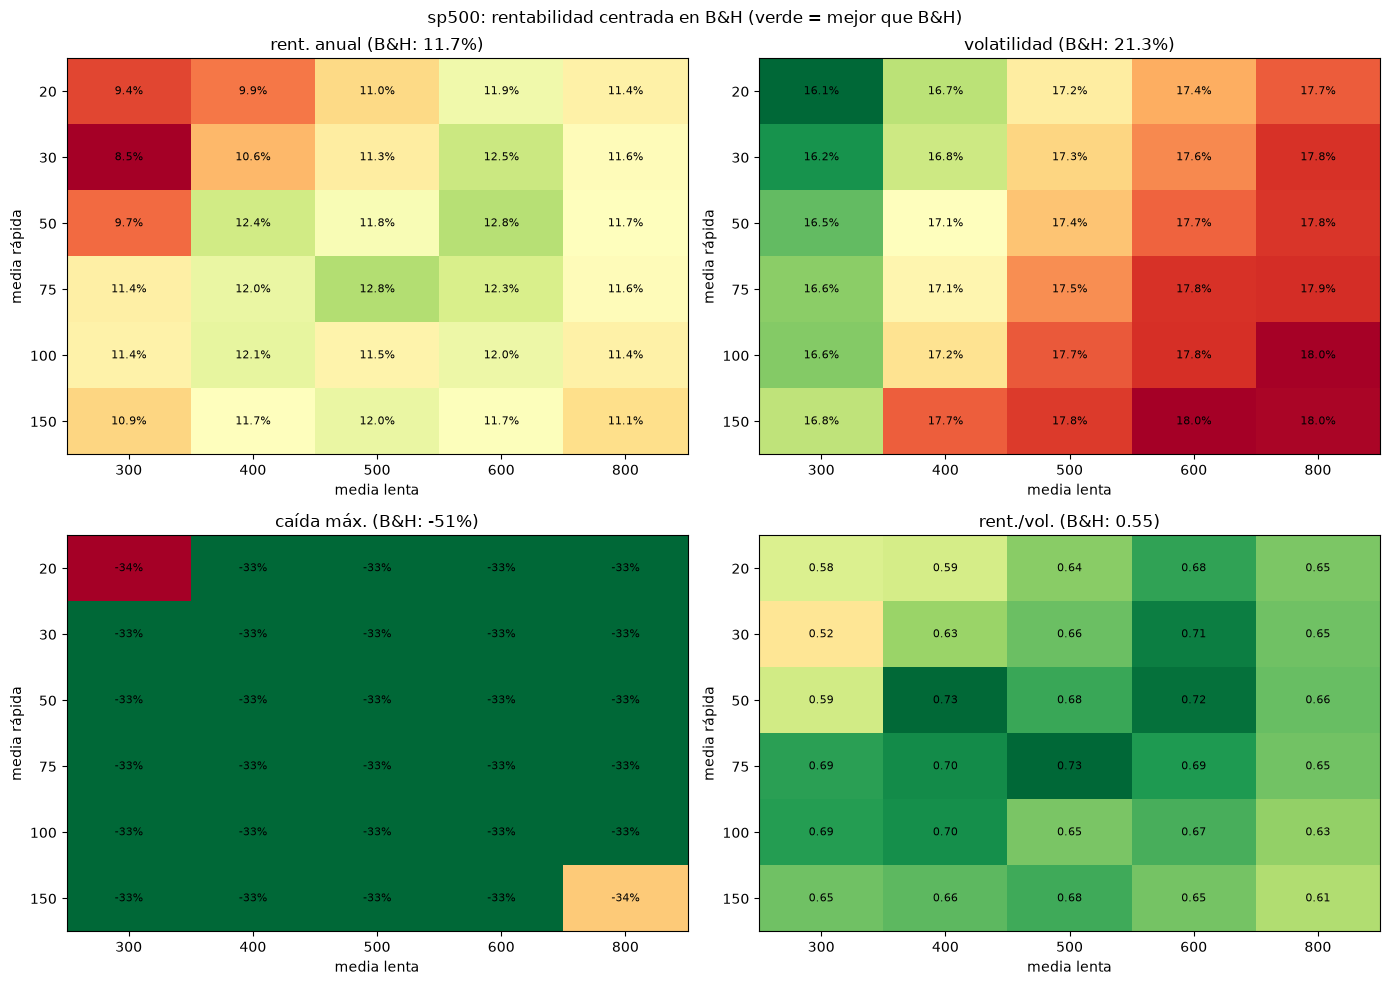

In [4]:
tabla = pd.DataFrame({k: metricas(diarias[k], ops[k]) for k in diarias}).T
bh = tabla.loc["B&H"]
comb = tabla.drop("B&H")
comb.index = pd.MultiIndex.from_tuples(comb.index, names=["rápida", "lenta"])
print("B&H:", ", ".join(f"{k} {v:.3f}" for k, v in bh.items()))


def mapa(ax, columna, formato, centro=None, cmap="RdYlGn"):
    m = comb[columna].unstack("lenta").reindex(index=RAPIDAS, columns=LENTAS)
    vmax = np.nanmax(np.abs(m.values - centro)) if centro is not None else None
    ax.imshow(m.values, cmap=cmap, aspect="auto",
              vmin=None if centro is None else centro - vmax, vmax=None if centro is None else centro + vmax)
    for i, a in enumerate(m.index):
        for j, b in enumerate(m.columns):
            if not np.isnan(m.iloc[i, j]):
                ax.text(j, i, formato.format(m.iloc[i, j]), ha="center", va="center", fontsize=8)
    ax.set(xticks=range(len(LENTAS)), xticklabels=LENTAS, yticks=range(len(RAPIDAS)), yticklabels=RAPIDAS,
           xlabel="media lenta", ylabel="media rápida", title=f"{columna} (B&H: {formato.format(bh[columna])})")


fig, axs = plt.subplots(2, 2, figsize=(14, 10))
mapa(axs[0, 0], "rent. anual", "{:.1%}", centro=bh["rent. anual"])
mapa(axs[0, 1], "volatilidad", "{:.1%}", cmap="RdYlGn_r")
mapa(axs[1, 0], "caída máx.", "{:.0%}")
mapa(axs[1, 1], "rent./vol.", "{:.2f}", centro=bh["rent./vol."])
fig.suptitle(f"{ACTIVO}: rentabilidad centrada en B&H (verde = mejor que B&H)")
fig.tight_layout()

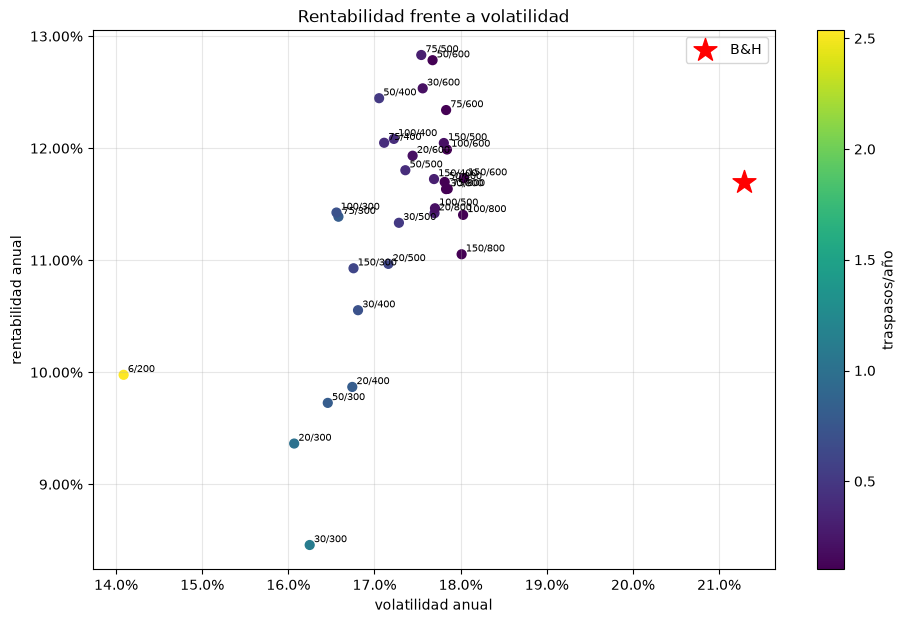

In [5]:
fig, ax = plt.subplots(figsize=(11, 7))
sc = ax.scatter(comb["volatilidad"], comb["rent. anual"], c=comb["traspasos/año"], cmap="viridis", s=40)
for (a, b), fila in comb.iterrows():
    ax.annotate(f"{a}/{b}", (fila["volatilidad"], fila["rent. anual"]), fontsize=7,
                xytext=(3, 2), textcoords="offset points")
ax.scatter(bh["volatilidad"], bh["rent. anual"], marker="*", s=300, color="red", label="B&H")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set(xlabel="volatilidad anual", ylabel="rentabilidad anual", title="Rentabilidad frente a volatilidad")
fig.colorbar(sc, label="traspasos/año"); ax.legend(); ax.grid(alpha=0.3)

Las 10 combinaciones con más rentabilidad, y las 10 con menos volatilidad entre las que rinden como mucho 1 punto menos que B&H:

In [6]:
fmt = {"rent. anual": "{:.1%}", "volatilidad": "{:.1%}", "rent./vol.": "{:.2f}",
       "caída máx.": "{:.0%}", "rent./caída": "{:.2f}", "traspasos/año": "{:.1f}"}
display(comb.sort_values("rent. anual", ascending=False).head(10).style.format(fmt))
cerca = comb[comb["rent. anual"] >= bh["rent. anual"] - 0.01]
display(cerca.sort_values("volatilidad").head(10).style.format(fmt))

,,rent. anual,volatilidad,rent./vol.,caída máx.,rent./caída,traspasos/año
rápida,lenta,,,,,,
75,500,12.8%,17.5%,0.73,-33%,0.39,0.3
50,600,12.8%,17.7%,0.72,-33%,0.39,0.1
30,600,12.5%,17.6%,0.71,-33%,0.38,0.2
50,400,12.4%,17.1%,0.73,-33%,0.38,0.5
75,600,12.3%,17.8%,0.69,-33%,0.37,0.1
100,400,12.1%,17.2%,0.70,-33%,0.37,0.4
75,400,12.0%,17.1%,0.70,-33%,0.36,0.4
150,500,12.0%,17.8%,0.68,-33%,0.36,0.2
100,600,12.0%,17.8%,0.67,-33%,0.36,0.1


,,rent. anual,volatilidad,rent./vol.,caída máx.,rent./caída,traspasos/año
rápida,lenta,,,,,,
100,300,11.4%,16.6%,0.69,-33%,0.35,0.7
75,300,11.4%,16.6%,0.69,-33%,0.34,0.8
150,300,10.9%,16.8%,0.65,-33%,0.33,0.6
50,400,12.4%,17.1%,0.73,-33%,0.38,0.5
75,400,12.0%,17.1%,0.70,-33%,0.36,0.4
20,500,11.0%,17.2%,0.64,-33%,0.33,0.6
100,400,12.1%,17.2%,0.70,-33%,0.37,0.4
30,500,11.3%,17.3%,0.66,-33%,0.34,0.5
50,500,11.8%,17.4%,0.68,-33%,0.36,0.4


## 2. Perspectiva en el tiempo

Para cada combinación, rentabilidad anualizada en todas las ventanas de `VENTANA` años (desplazándose día a día) menos la de B&H en la misma ventana. Mide si una combinación gana de forma repetida o solo gracias a un episodio concreto.

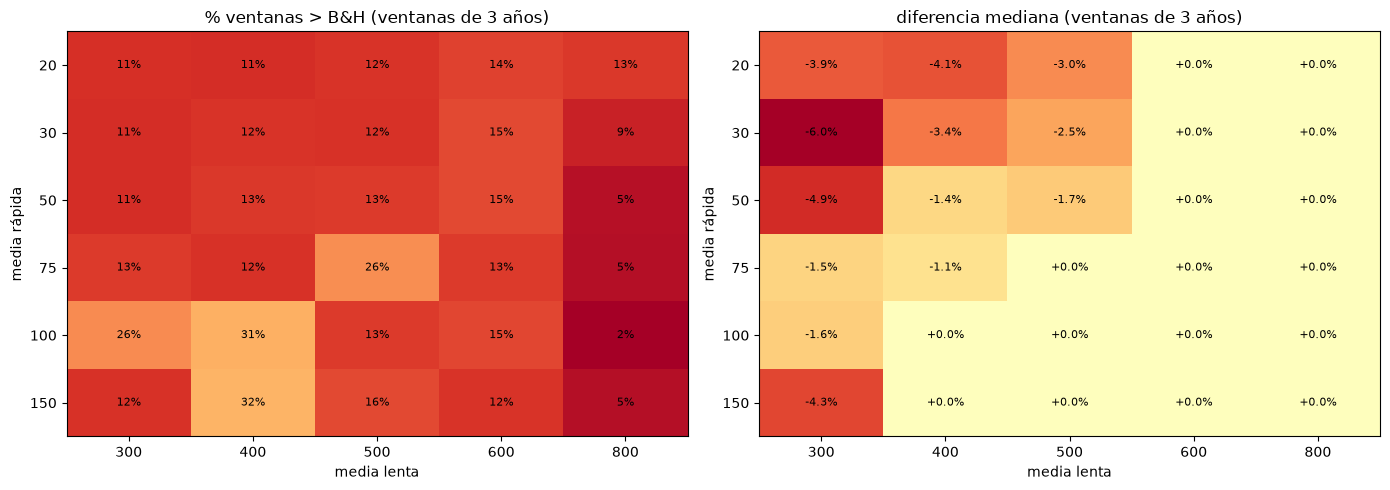

In [7]:
movil_bh = rent_movil(rent, VENTANA)
dif = pd.DataFrame({k: rent_movil(diarias[k], VENTANA) - movil_bh for k in combinaciones}).dropna()

resumen_movil = pd.DataFrame({
    "% ventanas > B&H": (dif > 0).mean(),
    "diferencia mediana": dif.median(),
    "peor diferencia": dif.min(),
    "mejor diferencia": dif.max(),
})
resumen_movil.index = pd.MultiIndex.from_tuples(resumen_movil.index, names=["rápida", "lenta"])

fig, axs = plt.subplots(1, 2, figsize=(14, 5))
for ax, col, f in [(axs[0], "% ventanas > B&H", "{:.0%}"), (axs[1], "diferencia mediana", "{:+.1%}")]:
    m = resumen_movil[col].unstack("lenta").reindex(index=RAPIDAS, columns=LENTAS)
    centro = 0.5 if col.startswith("%") else 0
    v = np.nanmax(np.abs(m.values - centro))
    ax.imshow(m.values, cmap="RdYlGn", aspect="auto", vmin=centro - v, vmax=centro + v)
    for i in range(len(RAPIDAS)):
        for j in range(len(LENTAS)):
            if not np.isnan(m.iloc[i, j]):
                ax.text(j, i, f.format(m.iloc[i, j]), ha="center", va="center", fontsize=8)
    ax.set(xticks=range(len(LENTAS)), xticklabels=LENTAS, yticks=range(len(RAPIDAS)), yticklabels=RAPIDAS,
           xlabel="media lenta", ylabel="media rápida", title=f"{col} (ventanas de {VENTANA} años)")
fig.tight_layout()

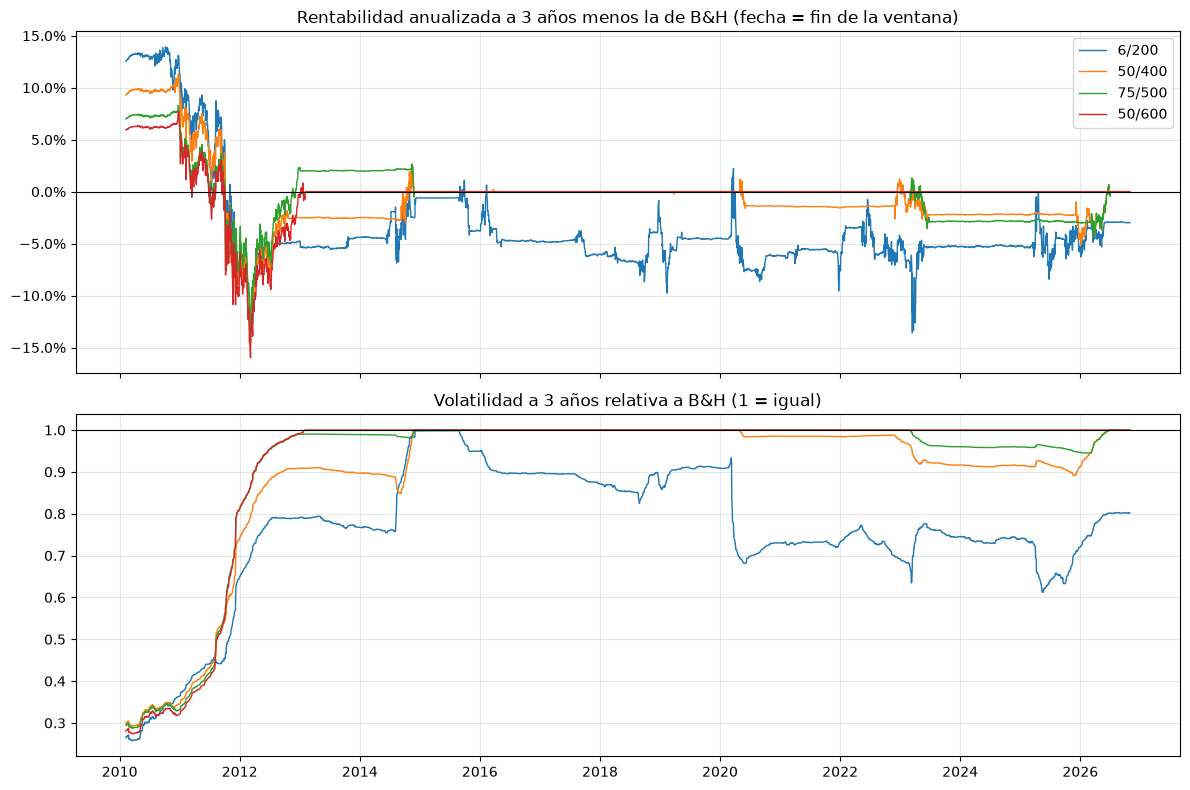

In [8]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for k in DESTACADAS:
    ax1.plot(dif[k], lw=1, label=f"{k[0]}/{k[1]}")
    vol_k = diarias[k].rolling(int(252 * VENTANA)).std()
    vol_bh = rent.rolling(int(252 * VENTANA)).std()
    ax2.plot((vol_k / vol_bh).dropna(), lw=1, label=f"{k[0]}/{k[1]}")
ax1.axhline(0, color="black", lw=0.8); ax2.axhline(1, color="black", lw=0.8)
ax1.set(title=f"Rentabilidad anualizada a {VENTANA} años menos la de B&H (fecha = fin de la ventana)")
ax2.set(title=f"Volatilidad a {VENTANA} años relativa a B&H (1 = igual)")
ax1.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax1.legend(); ax1.grid(alpha=0.3); ax2.grid(alpha=0.3)
fig.tight_layout()

### Estabilidad entre mitades

Rentabilidad anual menos la de B&H, calculada por separado en la primera y en la segunda mitad del periodo. Si la zona buena es la misma en ambas, es más probable que sea un efecto real que una casualidad.

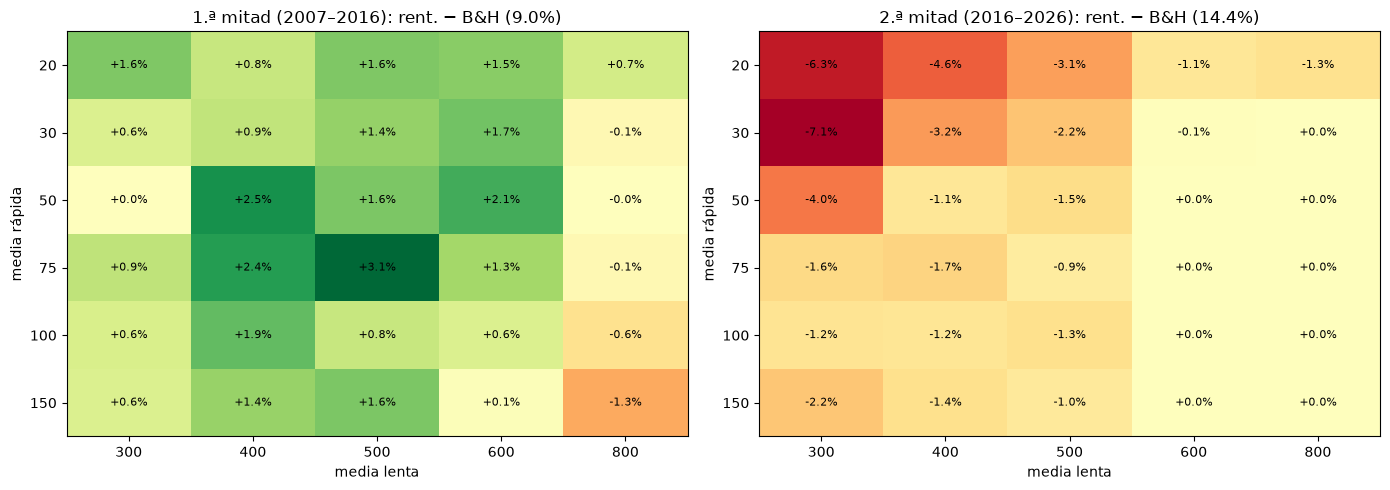

In [9]:
mitad = rent.index[len(rent) // 2]
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
for ax, tramo, nombre in [(axs[0], slice(None, mitad), "1.ª mitad"), (axs[1], slice(mitad, None), "2.ª mitad")]:
    ref = metricas(rent.loc[tramo], ops["B&H"].loc[tramo])["rent. anual"]
    vals = {k: metricas(diarias[k].loc[tramo], ops[k].loc[tramo])["rent. anual"] - ref for k in combinaciones}
    m = pd.Series(vals).unstack().reindex(index=RAPIDAS, columns=LENTAS)
    v = np.nanmax(np.abs(m.values))
    ax.imshow(m.values, cmap="RdYlGn", aspect="auto", vmin=-v, vmax=v)
    for i in range(len(RAPIDAS)):
        for j in range(len(LENTAS)):
            if not np.isnan(m.iloc[i, j]):
                ax.text(j, i, f"{m.iloc[i, j]:+.1%}", ha="center", va="center", fontsize=8)
    t = rent.loc[tramo].index
    ax.set(xticks=range(len(LENTAS)), xticklabels=LENTAS, yticks=range(len(RAPIDAS)), yticklabels=RAPIDAS,
           xlabel="media lenta", ylabel="media rápida",
           title=f"{nombre} ({t[0]:%Y}–{t[-1]:%Y}): rent. − B&H ({ref:.1%})")
fig.tight_layout()

## 3. Episodios fuera del mercado

Para cada combinación destacada, cada periodo fuera: cuándo salta la señal de salida y la de entrada, y cuánto varió el activo entre las dos ejecuciones (`RETRASO` sesiones después de cada señal). **Negativo = caída evitada; positivo = subida perdida.** Con medias lentas hay pocos episodios, así que el resultado global depende de muy pocos de ellos.

In [10]:
def episodios(a, b):
    d = posicion(precio, ((a, b),)).loc[rent.index[0]:]
    filas = []
    for _, tramo in d.groupby(d.ne(d.shift()).cumsum()):
        if tramo.iloc[0]:
            continue
        i_sal = precio.index.get_loc(tramo.index[0])
        i_ent = precio.index.get_loc(tramo.index[-1]) + 1
        sigue = i_ent >= len(precio)
        p_sal = precio.iloc[min(i_sal + RETRASO, len(precio) - 1)]
        p_ent = precio.iloc[-1] if sigue else precio.iloc[min(i_ent + RETRASO, len(precio) - 1)]
        filas.append({
            "salida": tramo.index[0].date(),
            "entrada": "sigue fuera" if sigue else precio.index[i_ent].date(),
            "sesiones fuera": len(tramo),
            "variación del activo": p_ent / p_sal - 1,
        })
    return pd.DataFrame(filas)


for a, b in DESTACADAS:
    ep = episodios(a, b)
    print(f"{a}/{b}: {len(ep)} episodios fuera · producto de variaciones {(1 + ep['variación del activo']).prod() - 1:+.1%}")
    display(ep.style.format({"variación del activo": "{:+.1%}"})
              .background_gradient(cmap="RdYlGn_r", subset="variación del activo", vmin=-0.3, vmax=0.3))

6/200: 25 episodios fuera · producto de variaciones +35.9%


,salida,entrada,sesiones fuera,variación del activo
0,2007-07-31,2007-10-04,46,+3.0%
1,2007-10-19,2009-06-12,414,-35.5%
2,2009-06-17,2009-07-17,21,+2.0%
3,2010-10-05,2010-10-25,14,+2.6%
4,2011-06-07,2011-07-05,19,+7.1%
5,2011-07-29,2011-10-28,64,+0.6%
6,2011-11-01,2011-11-02,1,-1.6%
7,2011-11-23,2011-12-01,5,+4.6%
8,2012-12-28,2013-01-02,2,+1.5%
9,2015-08-25,2015-10-28,45,+8.2%


50/400: 5 episodios fuera · producto de variaciones -12.3%


,salida,entrada,sesiones fuera,variación del activo
0,2007-11-28,2009-10-21,478,-25.4%
1,2011-09-01,2011-11-17,54,+6.9%
2,2016-03-18,2016-03-23,3,+0.0%
3,2020-04-28,2020-06-02,24,+3.8%
4,2022-11-25,2023-06-15,138,+6.0%


75/500: 3 episodios fuera · producto de variaciones -18.0%


,salida,entrada,sesiones fuera,variación del activo
0,2007-12-18,2009-12-29,511,-20.0%
1,2011-11-08,2011-11-22,10,-5.0%
2,2023-02-27,2023-06-23,81,+7.9%


50/600: 1 episodios fuera · producto de variaciones -17.3%


,salida,entrada,sesiones fuera,variación del activo
0,2007-12-13,2010-01-29,535,-17.3%


## 4. Señales de las combinaciones lentas

Todo el periodo, una fila por combinación: precio (escala logarítmica), sus dos medias, periodos fuera sombreados en rojo, ▼ salida y ▲ entrada. En el título, la variación del activo en cada episodio fuera (negativo = caída evitada, positivo = subida perdida).

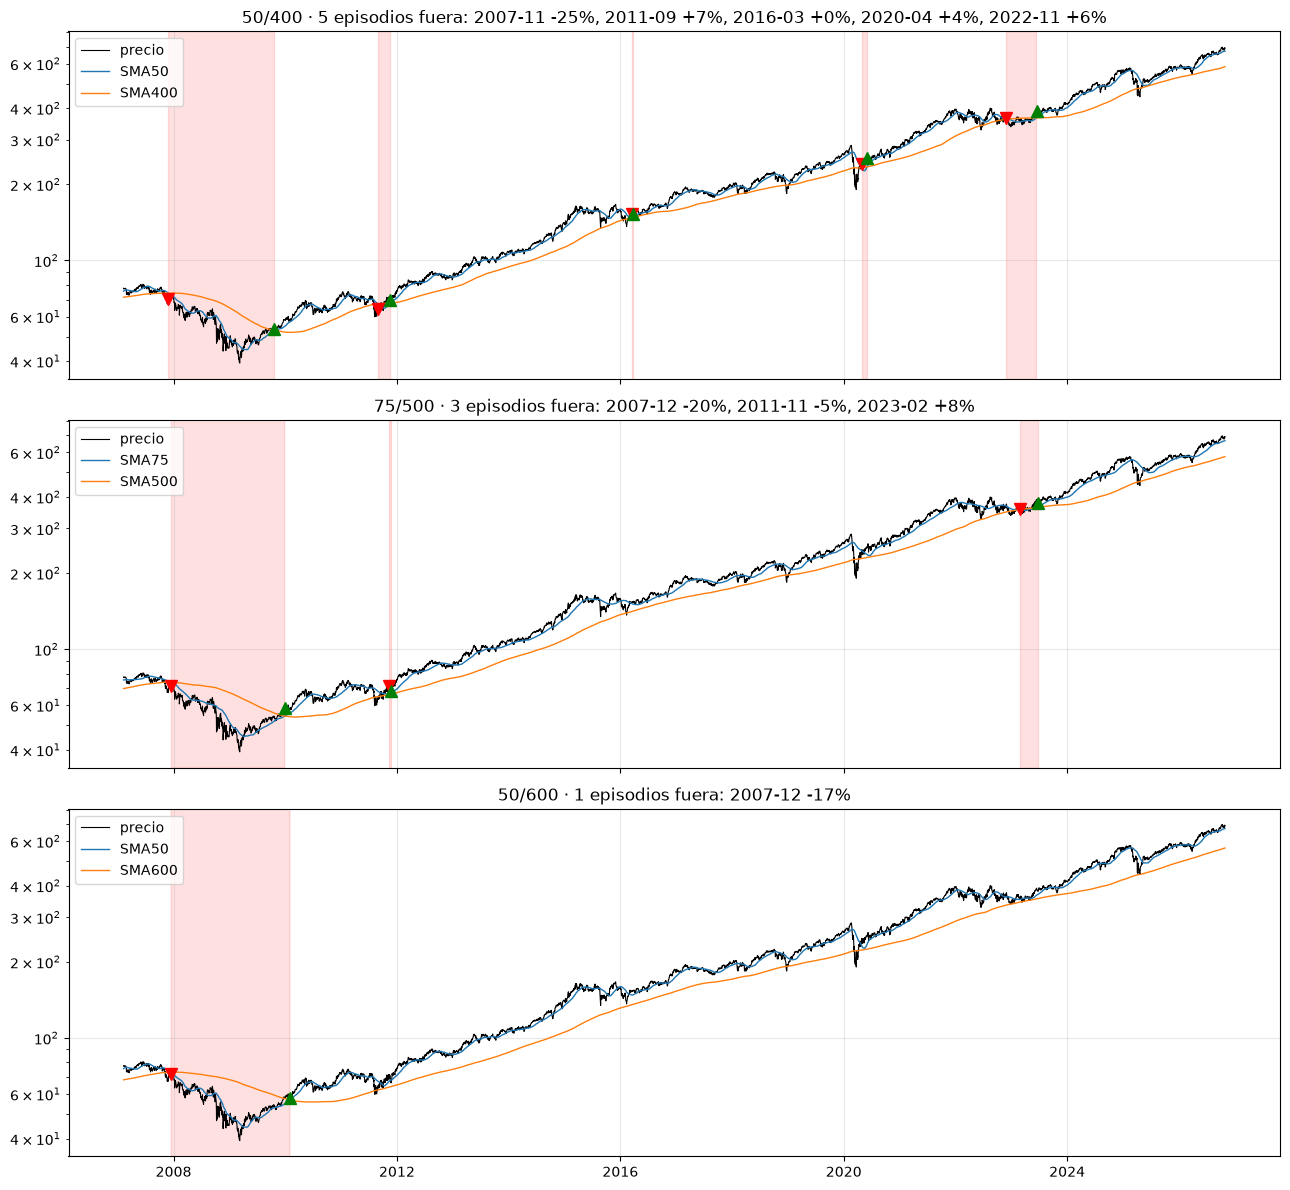

In [11]:
fig, axs = plt.subplots(len(GRAFICO_SENALES), 1, figsize=(13, 4 * len(GRAFICO_SENALES)), sharex=True)
axs = np.atleast_1d(axs)
p = precio.loc[rent.index[0]:]
for ax, (a, b) in zip(axs, GRAFICO_SENALES):
    dentro = posicion(precio, ((a, b),)).loc[p.index[0]:]
    ax.plot(p, color="black", lw=0.8, label="precio")
    ax.plot(precio.rolling(a).mean().loc[p.index[0]:], lw=1, label=f"SMA{a}")
    ax.plot(precio.rolling(b).mean().loc[p.index[0]:], lw=1, label=f"SMA{b}")
    ax.fill_between(dentro.index, 0, 1, where=~dentro, transform=ax.get_xaxis_transform(), color="red", alpha=0.12)
    cambios = dentro[dentro.ne(dentro.shift())].iloc[1:]
    for fecha, entra in cambios.items():
        ax.plot(fecha, p[fecha], "^" if entra else "v", color="green" if entra else "red", ms=9)
    ep = episodios(a, b)
    detalle = ", ".join(f"{str(f)[:7]} {v:+.0%}" for f, v in zip(ep["salida"], ep["variación del activo"]))
    ax.set(yscale="log", title=f"{a}/{b} · {len(ep)} episodios fuera: {detalle}")
    ax.legend(loc="upper left"); ax.grid(alpha=0.3)
fig.tight_layout()